# Notebook 2: LLM

In [44]:
# Importerer libraries
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from openai import OpenAI
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import time
from concurrent.futures import ThreadPoolExecutor

### Oppsett av OpenAI API

In [45]:
# leser nøkkelen fra .env
load_dotenv()  

# kobler til OpenAI med API-nøkkelen
client = OpenAI()    

In [46]:
# Skriver ut alle Luna-modellene vi har tilgang på gjennom API-et
luna_modeller = sorted(i.id for i in client.models.list() if 'luna' in i.id)
print(luna_modeller)

['gpt-5.6-luna', 'gpt-6-luna']


In [47]:
# Velger modell GPT-6 Luna
MODELL = 'gpt-6-luna' 

# Tester at oppsettet funker, med et enkelt spørsmål
svar = client.responses.create(
    model=MODELL,
    # Slår av resonnering  
    reasoning={'effort': 'none'},
    input='Svar med ett ord: hvilket dyr sier "mjau"?'
)

# Skriver ut teksten modellen svarte
print(svar.output_text)

# Skriver ut antall tokens modellen brukte
print(svar.usage)

Katt
ResponseUsage(input_tokens=18, input_tokens_details=InputTokensDetails(cache_write_tokens=0, cached_tokens=0), output_tokens=6, output_tokens_details=OutputTokensDetails(reasoning_tokens=0), total_tokens=24)


### Lager funksjonene for å klassifisere klager med LLM

In [48]:
# Lager en funksjon som tar inn én klagetekst og en prompt-funksjon, og returnerer kategorien LLM-en svarer
def klassifiser_en(klage, lag_prompt):
    # Prøver opptil tre ganger i tilfelle API-et feiler
    for i in range(3):
        try:
            # Lager prompten og sender den til modellen
            svar = client.responses.create(
                model=MODELL,
                reasoning={'effort': 'none'},
                input=lag_prompt(klage)
            )
            # Fjerner mellomrom og punktum slik at svaret blir likt kategorinavnet
            return svar.output_text.strip().rstrip('.')
        except Exception as feilmelding:
            # Skriver ut feilen og venter fem sekunder før neste forsøk
            print('Feil –', feilmelding)
            time.sleep(5)
    # Returnerer et tomt svar hvis alle tre forsøkene feilet
    return None   
    

# Lager en funksjon som sender åtte klager samtidig til LLM-en og lagrer svarene underveis
def klassifiser_raskt(klager_df, lag_prompt, svarkolonne, filnavn, antall=8):
    # Leser inn filen hvis den finnes, slik at tidligere svar ikke hentes på nytt
    if os.path.exists(filnavn):
        klager_df = pd.read_csv(filnavn)

    # Lager en tom svarkolonne hvis den ikke finnes fra før
    if svarkolonne not in klager_df.columns:
        klager_df[svarkolonne] = None

    # Skriver ut hvor mange klager som ennå ikke har blitt klassifisert
    uten_svar = klager_df.index[klager_df[svarkolonne].isna()].tolist()
    print('Gjenstår:', len(uten_svar))

    # Går gjennom klagene uten svar i bolker på 100
    for start in range(0, len(uten_svar), 100):
        # Henter radnumrene og klagetekstene i bolken
        bolk = uten_svar[start:start + 100]
        klager = klager_df.loc[bolk, 'Consumer complaint narrative']

        # Sender klagene til klassifiser_en parallelt, og samler svarene i en liste
        with ThreadPoolExecutor(max_workers=antall) as pool:
            svar = list(pool.map(lambda k: klassifiser_en(k, lag_prompt), klager))

        # Lagrer svarene i tabellen og lagrer tabellen til en csv-fil etter hver bolk
        klager_df.loc[bolk, svarkolonne] = svar
        klager_df.to_csv(filnavn, index=False)
        print(start + len(bolk), 'av', len(uten_svar), 'ferdig')

    # Returnerer tabellen med alle svarene
    return klager_df

### Leser inn valideringssettet

In [49]:
# Leser inn valideringssettet
valid_df = pd.read_csv('valideringssett.csv')   

# Sorterer problemkategoriene i alfabetisk rekkefølge og skriver ut  
kategorier = sorted(valid_df['Issue'].unique())
print(kategorier)

['Advertising and marketing, including promotional offers', 'Closing your account', 'Fees or interest', 'Getting a credit card', 'Other features, terms, or problems', 'Problem when making payments', 'Problem with a purchase shown on your statement']


### Promt A: Kun kategorinavn

#### Lager prompt A:

In [50]:
# Lager prompt A, som kun inneholder kategorinavnene
def prompt_a(klage):
    # Lager en punktliste med problemkategoriene 
    kategoriliste = '\n'.join('- ' + k for k in kategorier)
    return f'''Classify the following credit card complaint into exactly one of these categories:
{kategoriliste}

XXXX indicates anonymized information.
Answer with the category name only, exactly as written above.

Complaint:
{klage}'''

# Viser hvordan prompten ser ut for den første klagen i valideringssettet
print(prompt_a(valid_df['Consumer complaint narrative'].iloc[0]))

Classify the following credit card complaint into exactly one of these categories:
- Advertising and marketing, including promotional offers
- Closing your account
- Fees or interest
- Getting a credit card
- Other features, terms, or problems
- Problem when making payments
- Problem with a purchase shown on your statement

XXXX indicates anonymized information.
Answer with the category name only, exactly as written above.

Complaint:
Contacted Capital One Credit on XXXX XXXX, 2017 regarding denying my access to online banking account to pay my credit card bill. I tried to access my credit card account with the same user id and the same password as I have always used and was denied further access to look at my credit card account information unless I provided my income information and employment status to the company. After calling the company and speaking to a representative and an IT technician I was told that I must provide this information in order to have access to my online accou

#### Klassifisering av valideringssettet med prompt A:

In [51]:
valid_df = klassifiser_raskt(valid_df, prompt_a, 'svar_a', 'llm_validering.csv')

Gjenstår: 0


#### Resultater:

In [52]:
# Sjekker om noen svar mangler eller er ugyldige
print('Manglende svar:', valid_df['svar_a'].isna().sum())
print('Ugyldige svar:', (~valid_df['svar_a'].isin(kategorier)).sum())

# Sammenligner svarene fra LLM-en med fasiten
print(classification_report(valid_df['Issue'], valid_df['svar_a'], zero_division=0))

Manglende svar: 0
Ugyldige svar: 0
                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.57      0.71      0.63       169
                                   Closing your account       0.71      0.77      0.74       172
                                       Fees or interest       0.76      0.73      0.75       299
                                  Getting a credit card       0.76      0.71      0.73       171
                     Other features, terms, or problems       0.46      0.42      0.44       306
                           Problem when making payments       0.59      0.73      0.65       215
        Problem with a purchase shown on your statement       0.92      0.79      0.85       460

                                               accuracy                           0.69      1792
                                              macro avg       0.68      0.70      0.68    

### Promt B: Kategorinavn med beskrivelser og regler

In [53]:
# Lager en ordbok der hver problemkategori kobles til en kort beskrivelse (underkategorier)
beskrivelser = {
    'Problem with a purchase shown on your statement': 'disputes about purchases not being resolved, charges for something not purchased, or being overcharged',
    'Fees or interest': 'problems with fees, too much interest charged, or unexpected increases in interest rate',
    'Problem when making payments': 'problems during the payment process, or not receiving a bill or not knowing a payment was due',
    'Closing your account': 'the company closed the account, or the consumer cannot close the account',
    'Getting a credit card': 'cards opened through identity theft or fraud, denied applications, cards never applied for, delays in applications, or problems getting a replacement card',
    'Advertising and marketing, including promotional offers': 'not receiving advertised or promotional terms, or confusing or misleading advertising',
    'Other features, terms, or problems': 'rewards, customer service, balance transfers, privacy, add-on products, cash advances, arbitration, convenience checks, or other problems',
}

# Lager prompt B, som inneholder kategorinavn med beskrivelser og noen regler
def prompt_b(klage):
    # Lager en punktliste med problemkategoriene og tilhørende beskrivelsr
    kategoriliste = '\n'.join(f'- {k}: {beskrivelser[k]}' for k in kategorier)
    return f'''Classify the following credit card complaint into exactly one of these categories:
{kategoriliste}

If the complaint fits several categories, choose the one that describes the main problem.
Use "Other features, terms, or problems" only if none of the other categories fit.

XXXX indicates anonymized information.
Answer with the category name only, exactly as written before the colon.

Complaint:
{klage}'''

# Viser hvordan prompten ser ut for den første klagen i valideringssettet
print(prompt_b(valid_df['Consumer complaint narrative'].iloc[0]))

Classify the following credit card complaint into exactly one of these categories:
- Advertising and marketing, including promotional offers: not receiving advertised or promotional terms, or confusing or misleading advertising
- Closing your account: the company closed the account, or the consumer cannot close the account
- Fees or interest: problems with fees, too much interest charged, or unexpected increases in interest rate
- Getting a credit card: cards opened through identity theft or fraud, denied applications, cards never applied for, delays in applications, or problems getting a replacement card
- Other features, terms, or problems: rewards, customer service, balance transfers, privacy, add-on products, cash advances, arbitration, convenience checks, or other problems
- Problem when making payments: problems during the payment process, or not receiving a bill or not knowing a payment was due
- Problem with a purchase shown on your statement: disputes about purchases not being

In [54]:
valid_df = klassifiser_raskt(valid_df, prompt_b, 'svar_b', 'llm_validering.csv')

Gjenstår: 0


In [55]:
# Sjekk om noen svar mangler eller er ugyldige
print('Manglende svar:', valid_df['svar_b'].isna().sum())
print('Ugyldige svar:', (~valid_df['svar_b'].isin(kategorier)).sum())

# Resultater
print(classification_report(valid_df['Issue'], valid_df['svar_b'], zero_division=0))

Manglende svar: 0
Ugyldige svar: 0
                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.56      0.75      0.64       169
                                   Closing your account       0.73      0.83      0.78       172
                                       Fees or interest       0.83      0.64      0.72       299
                                  Getting a credit card       0.70      0.82      0.76       171
                     Other features, terms, or problems       0.55      0.47      0.51       306
                           Problem when making payments       0.61      0.76      0.68       215
        Problem with a purchase shown on your statement       0.90      0.80      0.85       460

                                               accuracy                           0.71      1792
                                              macro avg       0.70      0.73      0.70    

### Leser inn testsettet

In [56]:
test_df = pd.read_csv('testsett.csv')

### Klassifisering av testsettet med promt B

In [57]:
# Klassifiserer alle klagene i testsettet med promt B
# Svarene lagres i kolonnen 'svar_llm' og i filen 'llm_test.csv' underveis
test_df = klassifiser_raskt(test_df, prompt_b, 'svar_llm', 'llm_test.csv')

Gjenstår: 0


In [62]:
# Sjekker om noen svar mangler eller er ugyldige
print('Manglende svar:', test_df['svar_llm'].isna().sum())
print('Ugyldige svar:', (~test_df['svar_llm'].isin(kategorier)).sum())

Manglende svar: 0
Ugyldige svar: 0


### Evaluering av LLM på testsettet

In [63]:
# Sammenligner svarene fra LLM-en med fasiten
print('LLM ZERO-SHOT, VARIANT B (testsett)')
print(classification_report(test_df['Issue'], test_df['svar_llm'], zero_division=0))

LLM ZERO-SHOT, VARIANT B (testsett)
                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.62      0.74      0.68       338
                                   Closing your account       0.73      0.85      0.79       343
                                       Fees or interest       0.82      0.65      0.73       598
                                  Getting a credit card       0.73      0.88      0.80       342
                     Other features, terms, or problems       0.55      0.53      0.54       612
                           Problem when making payments       0.60      0.72      0.66       430
        Problem with a purchase shown on your statement       0.92      0.79      0.85       920

                                               accuracy                           0.72      3583
                                              macro avg       0.71      0.74      0.72   

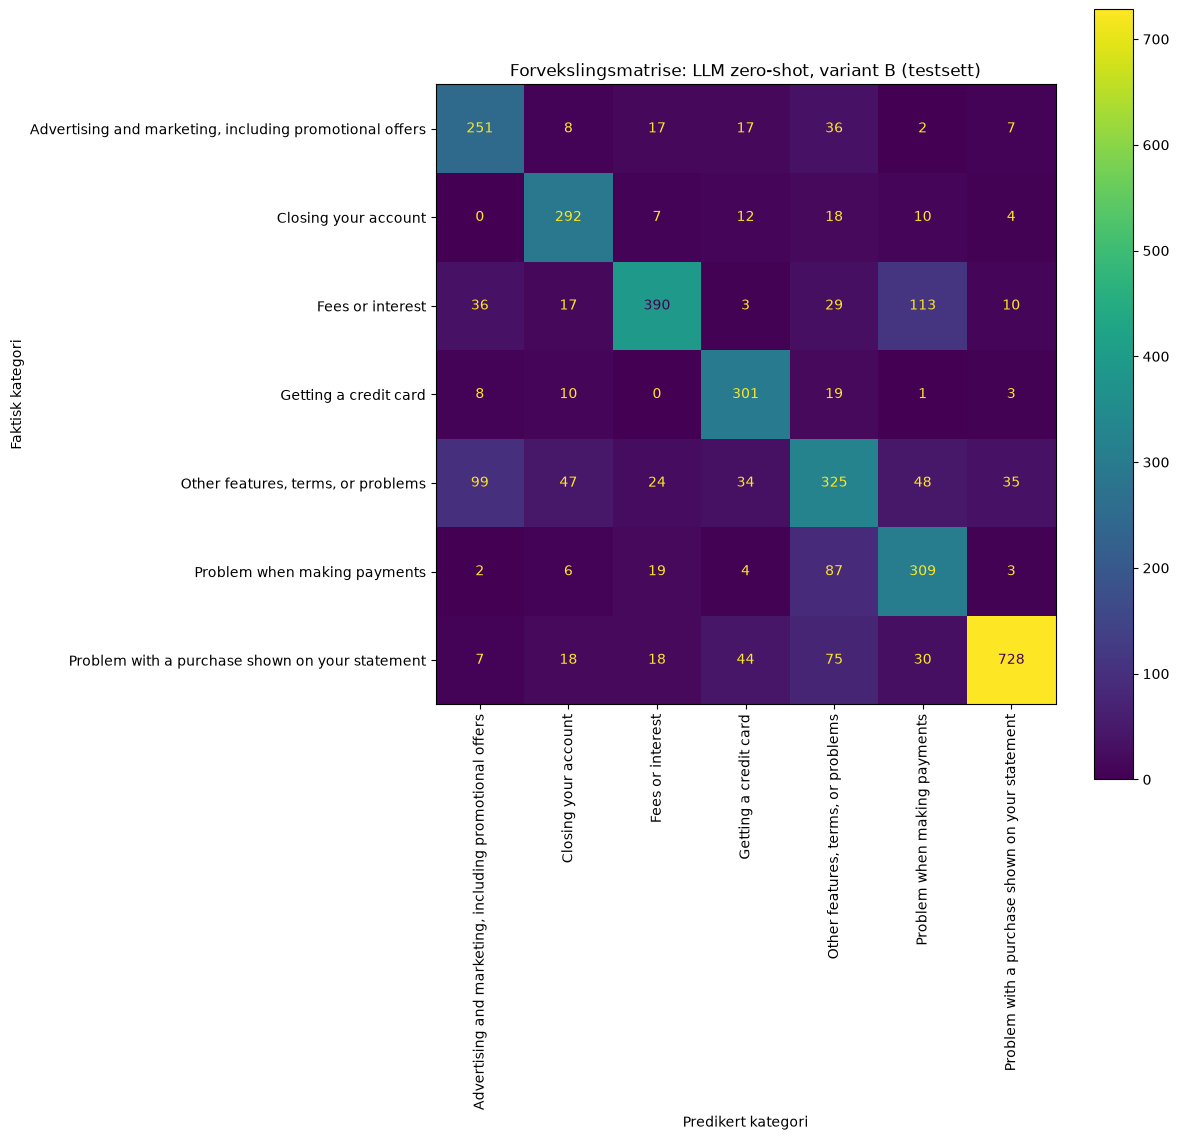

In [64]:
# Lager forvekslingsmatrise
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(test_df['Issue'], test_df['svar_llm'], xticks_rotation=90, ax=ax)
ax.set_title('Forvekslingsmatrise: LLM zero-shot, variant B (testsett)')
ax.set_xlabel('Predikert kategori')
ax.set_ylabel('Faktisk kategori')
plt.savefig('forvekslingsmatrise_llm.png', bbox_inches='tight', dpi=200)
plt.show()

### Dokumentasjon av LLM-kjøringen på testsettet

In [65]:
print('Modell:', MODELL)
print('API: OpenAI')
print('Innstilling: reasoning effort = none')
print('Prompt: variant B (kategorinavn med beskrivelser og regler)')
print('Antall klager i testsettet:', len(test_df))
print('Kjøringen ble gjort: 2026-10-23')

Modell: gpt-6-luna
API: OpenAI
Innstilling: reasoning effort = none
Prompt: variant B (kategorinavn med beskrivelser og regler)
Antall klager i testsettet: 3583
Kjøringen ble gjort: 2026-10-23
